# Do 3D Gaussian Splatting watermarks survive compression?

Recent work watermarks 3D Gaussian Splatting (3DGS) scenes for copyright protection. **GaussianMarker**
(NeurIPS 2024) perturbs the Gaussians with the highest *uncertainty*. **GuardSplat** (CVPR 2025) optimises the
spherical-harmonic (SH) colour features of all Gaussians. In both, the bits are read back from **rendered
images** with a frozen 2D message decoder. At the same time, 3DGS files are huge, so people routinely **compress**
them: LightGaussian-style importance pruning, SH truncation and vector quantisation, low-bit quantisation. They
also **fine-tune** scenes, or **re-train** a fresh 3DGS from renders.

Nobody checks whether these *benign* operations remove the watermark. This notebook does:

1. Train clean 3DGS scenes (NeRF-synthetic) with `gsplat`.
2. Embed a 48-bit watermark with simplified re-implementations of the two embedding strategies
   (*which* Gaussians / parameters carry the message), using a shared public pretrained decoder: the 48-bit HiDDeN
   extractor from Stable Signature.
3. Attack every watermarked scene with pruning, SH truncation, SH vector quantisation, uniform quantisation,
   fine-tuning, render-then-retrain distillation and a full LightGaussian-like pipeline, and plot **bit accuracy
   against PSNR**.
4. Test a simple **fix**: embed only in the Gaussians that survive pruning (high importance), optionally with
   compression-aware augmentation during embedding.

All knobs are in the next cell. Everything runs on one Kaggle T4.

In [1]:
import os, math, time, json, subprocess
subprocess.run('pip install -q gsplat', shell=True)

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from gsplat import rasterization
from gsplat.strategy import DefaultStrategy

# ---------------- knobs ----------------
SMOKE = False
SCENES = ['lego', 'hotdog', 'ficus']
RES = 400                       # render / train resolution (NeRF-synthetic is 800x800)
TRAIN_ITERS = 7000              # clean 3DGS training
N_EVAL_VIEWS = 40               # held-out test views used for every evaluation
N_RANDOM_VIEWS = 200            # extra random camera poses used for embedding and for distillation
EMBED_ITERS = 1500
EMBED_LAMBDA = dict(GM=10.0, GS=20.0)  # fidelity-loss weight (render vs. clean render), calibrated on lego so that
                                       # both families land at a similar visual cost (0.73-0.85 bit accuracy, 39-44 dB PSNR)
EMBED_LR_SCALE = 3.0
UNCERT_FRAC = 0.2               # GaussianMarker-style: fraction of Gaussians (highest uncertainty) carrying the watermark
KEEP_FRAC = 0.34                # the fix: only the top-34% most important Gaussians (they survive 66% pruning)
PRUNE_RATIOS = [0.1, 0.3, 0.5, 0.66, 0.8, 0.9]
SH_DEGREES = [2, 1, 0]
VQ_SIZES = [4096, 1024, 256, 64]
QUANT_BITS = [8, 6, 4]
FT_STEPS = [100, 300, 1000]
DISTILL_ITERS = 3000
FPR = 1e-4                      # false-positive rate for the per-view detection threshold
SEED = 0
METHODS = ['GaussianMarker-style', 'GuardSplat-style', 'GM + importance', 'GS + importance', 'Robust (ours)']

if SMOKE:
    SCENES, TRAIN_ITERS, N_EVAL_VIEWS, N_RANDOM_VIEWS, EMBED_ITERS, DISTILL_ITERS = ['lego'], 1500, 8, 20, 150, 500
    PRUNE_RATIOS, VQ_SIZES, FT_STEPS = [0.66], [256], [100]

DEV = 'cuda'
OUT = '/kaggle/working' if os.path.exists('/kaggle/working') else './out'
FIG = f'{OUT}/figures'
os.makedirs(FIG, exist_ok=True)
COLORS = dict(zip(METHODS, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']))
MARKERS = dict(zip(METHODS, ['o', 's', '^', 'D', 'P']))
plt.rcParams.update({'figure.dpi': 90, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10})
try:  # keep the executed notebook small
    get_ipython().run_line_magic('config', "InlineBackend.figure_format = 'jpeg'")
except NameError:
    pass
torch.manual_seed(SEED); np.random.seed(SEED)
T0 = time.time()

def savefig(name, ext='png'):
    plt.savefig(f'{FIG}/{name}.{ext}', bbox_inches='tight', dpi=130)
    plt.show()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.5/6.5 MB 55.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 4.6 MB/s eta 0:00:00


## 1. Data: NeRF-synthetic scenes
Blender cameras (OpenGL convention) are converted to OpenCV world-to-camera matrices for `gsplat`. Images are
composited on a white background and downsampled to 400x400.

In [2]:
def find_input(name):
    for root, dirs, files in os.walk('/kaggle/input'):
        if name in dirs:
            return os.path.join(root, name)

DATA = find_input('nerf_synthetic')
print('data at', DATA)

def load_split(scene, split, n=None):
    meta = json.load(open(f'{DATA}/{scene}/transforms_{split}.json'))
    frames = meta['frames']
    if n: frames = frames[::max(1, len(frames) // n)][:n]
    focal = 0.5 * RES / math.tan(0.5 * meta['camera_angle_x'])
    imgs, vms = [], []
    for fr in frames:
        path = os.path.normpath(f"{DATA}/{scene}/{fr['file_path']}.png")
        a = np.asarray(Image.open(path).convert('RGBA').resize((RES, RES), Image.LANCZOS), np.float32) / 255
        imgs.append(a[..., :3] * a[..., 3:] + (1 - a[..., 3:]))
        c2w = np.array(fr['transform_matrix'], np.float32)
        c2w[:3, 1:3] *= -1                                  # OpenGL -> OpenCV
        vms.append(np.linalg.inv(c2w))
    K = torch.tensor([[focal, 0, RES / 2], [0, focal, RES / 2], [0, 0, 1]], dtype=torch.float32, device=DEV)
    return dict(imgs=torch.tensor(np.stack(imgs), device=DEV), viewmats=torch.tensor(np.stack(vms), device=DEV), K=K)

def random_viewmats(n, radius, min_z, seed):
    """Random cameras on a sphere looking at the origin (OpenCV convention), above height min_z."""
    g = np.random.default_rng(seed)
    vms = []
    while len(vms) < n:
        p = g.normal(size=3); p = radius * p / np.linalg.norm(p)
        if p[2] < min_z: continue
        f = -p / np.linalg.norm(p)
        r = np.cross(f, [0, 0, 1.0]); r /= np.linalg.norm(r)
        d = np.cross(f, r)
        c2w = np.eye(4); c2w[:3, 0], c2w[:3, 1], c2w[:3, 2], c2w[:3, 3] = r, d, f, p
        vms.append(np.linalg.inv(c2w))
    return torch.tensor(np.stack(vms), dtype=torch.float32, device=DEV)

def camera_centers(vms):
    return torch.linalg.inv(vms)[:, :3, 3]

data at /kaggle/input/datasets/nguyenhung1903/nerf-synthetic-dataset/nerf_synthetic


## 2. A minimal 3DGS trainer on top of `gsplat`
Standard recipe: random initialisation (100k points), L1 + D-SSIM loss, SH degree grown to 3, and gsplat's
`DefaultStrategy` for densification/pruning. The same function is used for clean training, fine-tuning
(no densification, from given Gaussians) and distillation (from scratch on rendered images).

In [3]:
C0 = 0.28209479177387814
BYTES_PER_GAUSSIAN = 59 * 4     # 3 + 3 + 4 + 1 + 48 float32 values

def init_gaussians(n=100_000):
    rgb = torch.rand(n, 3)
    g = dict(means=(torch.rand(n, 3) * 2 - 1) * 1.3, scales=torch.full((n, 3), math.log(0.02)),
             quats=torch.tensor([1.0, 0, 0, 0]).repeat(n, 1), opacities=torch.logit(torch.full((n,), 0.1)),
             sh0=((rgb - 0.5) / C0)[:, None], shN=torch.zeros(n, 15, 3))
    return {k: v.to(DEV) for k, v in g.items()}

def render(g, cams, idx, sh_degree=3):
    idx = list(idx)
    vm = cams['viewmats'][idx]
    K = cams['K'][None].expand(len(idx), 3, 3)
    colors = torch.cat([g['sh0'], g['shN']], 1)
    img, _, info = rasterization(g['means'], g['quats'], torch.exp(g['scales']), torch.sigmoid(g['opacities']),
                                 colors, vm, K, RES, RES, sh_degree=sh_degree,
                                 backgrounds=torch.ones(len(idx), 3, device=DEV), packed=False)
    return img, info

_win = torch.exp(-(torch.arange(11) - 5.0) ** 2 / (2 * 1.5 ** 2)); _win = _win / _win.sum()
SSIM_W = (_win[:, None] * _win[None]).expand(3, 1, 11, 11).contiguous().to(DEV)

def ssim(x, y):
    x, y = x.permute(0, 3, 1, 2), y.permute(0, 3, 1, 2)
    f = lambda z: F.conv2d(z, SSIM_W, padding=5, groups=3)
    mx, my = f(x), f(y)
    sxx, syy, sxy = f(x * x) - mx ** 2, f(y * y) - my ** 2, f(x * y) - mx * my
    c1, c2 = 0.01 ** 2, 0.03 ** 2
    return (((2 * mx * my + c1) * (2 * sxy + c2)) / ((mx ** 2 + my ** 2 + c1) * (sxx + syy + c2))).mean()

def photo_loss(img, gt):
    return 0.8 * (img - gt).abs().mean() + 0.2 * (1 - ssim(img, gt))

def psnr(a, b):
    return -10 * torch.log10(((a - b) ** 2).flatten(1).mean(1))

def train_gs(data, iters, init=None, densify=True, checkpoints=(), seed=SEED):
    """Train on data = dict(imgs, viewmats, K). Returns final Gaussians and {step: Gaussians} snapshots."""
    torch.manual_seed(seed)
    g = init_gaussians() if init is None else init
    params = torch.nn.ParameterDict({k: torch.nn.Parameter(v.detach().clone()) for k, v in g.items()})
    lrs = dict(means=1.6e-4 * SCENE_SCALE, scales=5e-3, quats=1e-3, opacities=5e-2, sh0=2.5e-3, shN=2.5e-3 / 20)
    if init is not None:
        lrs['means'] = 1.6e-6 * SCENE_SCALE     # fine-tuning uses the final position learning rate
    opts = {k: torch.optim.Adam([params[k]], lr=lrs[k], eps=1e-15) for k in params}
    decay = 0.01 ** (1 / iters) if init is None else 1.0
    if densify:
        strategy = DefaultStrategy(refine_start_iter=500, refine_stop_iter=int(0.6 * iters), reset_every=3000,
                                   refine_every=100, verbose=False)
        strategy.check_sanity(params, opts)
        state = strategy.initialize_state(scene_scale=SCENE_SCALE)
    snaps = {}
    n = len(data['imgs'])
    for step in range(iters):
        i = int(torch.randint(n, (1,)))
        deg = min(3, step // 1000) if init is None else 3
        img, info = render(params, data, [i], deg)
        loss = photo_loss(img, data['imgs'][[i]])
        if densify: strategy.step_pre_backward(params, opts, state, step, info)
        loss.backward()
        for o in opts.values():
            o.step(); o.zero_grad(set_to_none=True)
        opts['means'].param_groups[0]['lr'] *= decay
        if densify: strategy.step_post_backward(params, opts, state, step, info, packed=False)
        if step + 1 in checkpoints:
            snaps[step + 1] = {k: v.detach().clone() for k, v in params.items()}
    return {k: v.detach() for k, v in params.items()}, snaps

## 3. Watermark decoder, message and evaluation
All methods share one frozen, public 2D decoder: the 48-bit HiDDeN extractor released with *Stable Signature*
(Fernandez et al., ICCV 2023). A scene "carries" the watermark if renders from **held-out test views** decode to
the message. We report the mean **bit accuracy** over test views (50% = chance) and the **detection rate**: the
fraction of views whose number of correct bits passes a binomial test at a false-positive rate of 1e-4.

In [4]:
if not os.path.exists('dec_48b_whit.torchscript.pt'):
    subprocess.run('wget -q https://dl.fbaipublicfiles.com/ssl_watermarking/dec_48b_whit.torchscript.pt', shell=True)
DEC = torch.jit.load('dec_48b_whit.torchscript.pt').to(DEV).eval()
for p_ in DEC.parameters(): p_.requires_grad_(False)
N_BITS = 48
IM_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEV).view(1, 3, 1, 1)
IM_STD = torch.tensor([0.229, 0.224, 0.225], device=DEV).view(1, 3, 1, 1)

def decode(img):
    """48 bit logits; renders are resized to the decoder's native 256x256."""
    x = F.interpolate(img.permute(0, 3, 1, 2), size=(256, 256), mode='bilinear', antialias=True)
    with torch.autocast('cuda', dtype=torch.float16):
        return DEC((x - IM_MEAN) / IM_STD).float()

K_THR = next(k for k in range(N_BITS + 1) if sum(math.comb(N_BITS, i) for i in range(k, N_BITS + 1)) / 2 ** N_BITS <= FPR)
print(f'a view counts as "watermark detected" if >= {K_THR}/{N_BITS} bits are correct (FPR {FPR:g})')

@torch.no_grad()
def evaluate(g, test, msg, clean_test=None, size=None):
    accs, ps, pc = [], [], []
    for s in range(0, len(test['imgs']), 8):
        idx = range(s, min(s + 8, len(test['imgs'])))
        img = render(g, test, idx)[0].clamp(0, 1)
        accs += ((decode(img) > 0) == msg).float().mean(1).tolist()
        ps += psnr(img, test['imgs'][list(idx)]).tolist()
        if clean_test is not None: pc += psnr(img, clean_test[list(idx)]).tolist()
    acc = np.array(accs)
    return dict(bit_acc=acc.mean(), detect=np.mean(acc * N_BITS >= K_THR), psnr=np.mean(ps),
                psnr_vs_clean=np.mean(pc) if pc else np.nan, n_gauss=len(g['means']),
                size_mb=(size if size is not None else len(g['means']) * BYTES_PER_GAUSSIAN) / 1e6)

@torch.no_grad()
def render_all(g, cams, n=None):
    n = n or len(cams['viewmats'])
    return torch.cat([render(g, cams, range(s, min(s + 8, n)))[0].clamp(0, 1) for s in range(0, n, 8)])

a view counts as "watermark detected" if >= 38/48 bits are correct (FPR 0.0001)


## 4. Importance (LightGaussian) and uncertainty (GaussianMarker)
* **Importance** follows LightGaussian's global significance: how many pixels a Gaussian touches over all training
  views, times its opacity, times its normalised volume^0.1. We approximate the pixel count by the Gaussian's
  projected screen-space extent. Pruning removes the least important Gaussians.
* **Uncertainty** follows GaussianMarker's Laplace approximation: the inverse of the diagonal Fisher information,
  i.e. squared gradients of the photometric loss summed over training views and over each Gaussian's parameters.
  High uncertainty = the renders barely constrain that Gaussian, so perturbing it is nearly invisible.

In [5]:
@torch.no_grad()
def importance(g, cams):
    imp = torch.zeros(len(g['means']), device=DEV)
    for s in range(0, len(cams['viewmats']), 8):
        _, info = render(g, cams, range(s, min(s + 8, len(cams['viewmats']))))
        r = info['radii'].float()
        area = (r[..., 0] * r[..., 1]) if r.dim() == 3 else r ** 2
        imp += area.clamp(max=RES * RES).sum(0)
    vol = torch.exp(g['scales']).prod(1)
    vnorm = (vol / torch.quantile(vol[:100_000], 0.9)).clamp(max=1) ** 0.1
    return imp * torch.sigmoid(g['opacities']) * vnorm

def uncertainty(g, cams, n_views=40):
    p = {k: v.detach().clone().requires_grad_(True) for k, v in g.items()}
    fisher = {k: torch.zeros(len(g['means']), device=DEV) for k in g}
    for i in np.linspace(0, len(cams['imgs']) - 1, n_views).astype(int):
        img, _ = render(p, cams, [i])
        grads = torch.autograd.grad(F.mse_loss(img, cams['imgs'][[i]]), list(p.values()))
        for k, gr in zip(p, grads):
            fisher[k] += gr.pow(2).reshape(len(gr), -1).sum(1)
    tot = sum(f / f.mean().clamp_min(1e-30) for f in fisher.values())
    return 1 / (tot + 1e-12)

## 5. Watermark embedding
All methods start from the same clean scene, optimise for `EMBED_ITERS` steps on training and random views, and
use the same loss: bit-wise BCE of the decoded render + lambda x (L1 + D-SSIM) between the render and the clean
scene's render (fidelity). lambda was calibrated on lego so that both method families reach 0.73-0.85 bit accuracy (39-44 dB) at
a similar visual cost (see the embedding table in section 8). They differ in **what** is optimised:

| method | carrier Gaussians | optimised parameters | extras |
|---|---|---|---|
| GaussianMarker-style | top-20% **uncertainty** | all (position, shape, opacity, SH) | |
| GuardSplat-style | all | SH colour features | 2D distortion augmentation (noise, blur, resize, brightness) |
| GM + importance (fix) | top-20% uncertainty **among the top-34% importance** | all | |
| GS + importance (fix) | top-34% **importance** | SH | 2D augmentation |
| Robust (ours) | top-34% importance | SH | 2D augmentation + simulated compression (random importance pruning, SH truncation, SH noise) |

These are simplified re-implementations of the two papers' *embedding strategies*, not their full pipelines:
GuardSplat trains its own CLIP-based decoder, GaussianMarker also has a 3D point-cloud decoder, and both have
further tricks. Here every method uses the same public decoder, so the comparison isolates **where** the message
lives in the scene.

In [6]:
EMBED_LR = dict(means=5e-5, scales=1e-3, quats=1e-3, opacities=5e-3, sh0=1e-3, shN=1e-3)

def subset(g, keep):
    return {k: v[keep] for k, v in g.items()}

def aug2d(x):
    c = np.random.randint(5)
    if c == 1: x = x + 0.02 * torch.randn_like(x)
    if c == 2: x = F.avg_pool2d(x.permute(0, 3, 1, 2), 3, 1, 1).permute(0, 2, 3, 1)
    if c == 3: x = F.interpolate(F.interpolate(x.permute(0, 3, 1, 2), scale_factor=0.75, mode='bilinear'),
                                 size=(RES, RES), mode='bilinear').permute(0, 2, 3, 1)
    if c == 4: x = x * np.random.uniform(0.9, 1.1)
    return x

def carrier_mask(method, imp, unc):
    N = len(imp)
    important = imp >= torch.quantile(imp, 1 - KEEP_FRAC)
    if method in ('GaussianMarker-style', 'GM + importance'):
        cand = imp > 0
        if method == 'GM + importance': cand &= important
        score = torch.where(cand, unc, -1.0)
        mask = torch.zeros(N, dtype=torch.bool, device=DEV)
        mask[score.topk(min(int(UNCERT_FRAC * N), int(cand.sum()))).indices] = True
        return mask
    if method == 'GuardSplat-style':
        return torch.ones(N, dtype=torch.bool, device=DEV)
    return important

def embed(g, cams, msg, method, imp, unc, seed=SEED):
    torch.manual_seed(seed); np.random.seed(seed)
    gm_family = method in ('GaussianMarker-style', 'GM + importance')
    keys = list(EMBED_LR) if gm_family else ['sh0', 'shN']
    lam = EMBED_LAMBDA['GM' if gm_family else 'GS']
    mask = carrier_mask(method, imp, unc)
    delta = {k: torch.zeros_like(g[k], requires_grad=True) for k in keys}
    opt = torch.optim.Adam([{'params': [delta[k]], 'lr': EMBED_LR[k] * EMBED_LR_SCALE} for k in keys])
    target = msg.float()[None]
    n = len(cams['viewmats'])
    cut = torch.sort(imp).values
    for step in range(EMBED_ITERS):
        gw = {k: g[k] + delta[k] * mask.view(-1, *[1] * (g[k].dim() - 1)) if k in delta else g[k] for k in g}
        i = int(torch.randint(n, (1,)))
        deg, keep = 3, None
        if method == 'Robust (ours)':
            if np.random.rand() < 0.5:   # simulated importance pruning
                keep = imp >= cut[int(np.random.uniform(0, 0.8) * len(cut))]
                gw = subset(gw, keep)
            if np.random.rand() < 0.5:   # simulated SH truncation
                deg = np.random.randint(0, 4)
            if np.random.rand() < 0.3:   # simulated SH quantisation noise
                gw = dict(gw, shN=gw['shN'] + 0.02 * torch.randn_like(gw['shN']))
        img, _ = render(gw, cams, [i], deg)
        x = img if gm_family else aug2d(img)
        loss = F.binary_cross_entropy_with_logits(decode(x), target)
        with torch.no_grad():   # fidelity target: the clean scene under the same simulated compression
            clean = render(g if keep is None else subset(g, keep), cams, [i], deg)[0]
        loss = loss + lam * photo_loss(img, clean)
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        return {k: (g[k] + delta[k] * mask.view(-1, *[1] * (g[k].dim() - 1))).detach() if k in delta else g[k]
                for k in g}, mask

## 6. Benign operations ("attacks")
| operation | what it does | strengths |
|---|---|---|
| **pruning** | LightGaussian global-significance pruning, importance recomputed on the watermarked scene | 10-90% of Gaussians removed |
| **SH truncation** | drop higher SH bands (LightGaussian distils SH degree 3 -> 2) | keep degree 2, 1, 0 |
| **SH vector quantisation** | k-means codebook for the 48 SH coefficients of every Gaussian | 4096 ... 64 codes |
| **uniform quantisation** | every attribute channel min-max quantised | 8, 6, 4 bits |
| **fine-tuning** | continue training on the original training images | 100, 300, 1000 steps |
| **distillation** | render the scene from train + random views, train a fresh 3DGS on the renders | 3000 steps |
| **LightGaussian-like** | prune 66% -> 500 recovery steps -> SH degree 2 -> VQ 4096 -> 8-bit | |

In [7]:
def attack_prune(g, cams, ratio):
    imp = importance(g, cams)
    keep = imp >= torch.quantile(imp, ratio)
    return subset(g, keep), int(keep.sum()) * BYTES_PER_GAUSSIAN

def attack_sh_degree(g, deg):
    shN = g['shN'].clone(); shN[:, (deg + 1) ** 2 - 1:] = 0
    return dict(g, shN=shN), len(g['means']) * (11 + 3 * (deg + 1) ** 2) * 4

@torch.no_grad()
def kmeans(X, K, iters=10, seed=SEED):
    gen = torch.Generator(device=X.device).manual_seed(seed)
    C = X[torch.randperm(len(X), generator=gen, device=X.device)[:K]].clone()
    for _ in range(iters):
        a = torch.cat([torch.cdist(X[s:s + 32768], C).argmin(1) for s in range(0, len(X), 32768)])
        cnt = torch.bincount(a, minlength=K).float()
        S = torch.zeros_like(C).index_add_(0, a, X)
        C = torch.where(cnt[:, None] > 0, S / cnt.clamp_min(1)[:, None], C)
    return C, a

def attack_vq(g, K):
    X = torch.cat([g['sh0'].flatten(1), g['shN'].flatten(1)], 1)
    K = min(K, len(X))
    C, a = kmeans(X, K)
    Xq = C[a]
    size = len(X) * (11 * 4 + math.ceil(math.log2(K)) / 8) + K * 48 * 4
    return dict(g, sh0=Xq[:, :3].view(-1, 1, 3), shN=Xq[:, 3:].view(-1, 15, 3)), size

def attack_quant(g, bits):
    out = {}
    for k, v in g.items():
        f = v.flatten(1) if v.dim() > 1 else v[:, None]
        lo, hi = f.min(0).values, f.max(0).values
        q = torch.round((f - lo) / (hi - lo).clamp_min(1e-12) * (2 ** bits - 1))
        out[k] = (q / (2 ** bits - 1) * (hi - lo) + lo).view_as(v)
    return out, len(g['means']) * 59 * bits / 8

def attack_finetune(g, train, steps):
    _, snaps = train_gs(train, max(steps), init=g, densify=False, checkpoints=steps)
    return snaps

def attack_distill(g, train, rand_vms):
    vms = torch.cat([train['viewmats'], rand_vms])
    cams = dict(viewmats=vms, K=train['K'])
    data = dict(imgs=render_all(g, cams), viewmats=vms, K=train['K'])
    return train_gs(data, DISTILL_ITERS)[0]

def attack_lightgaussian(g, train):
    gp, _ = attack_prune(g, train, 0.66)
    gf = train_gs(train, 500, init=gp, densify=False)[0]
    gs, _ = attack_sh_degree(gf, 2)
    gv, _ = attack_vq(gs, 4096)
    gq, _ = attack_quant(gv, 8)
    n = len(gq['means'])
    return gq, n * 11 + n * 12 / 8 + 4096 * 27 * 2

## 7. Run all scenes
For each scene: train a clean 3DGS, embed the watermark with all five methods, then apply every benign operation
at every strength and evaluate on the held-out test views.

In [8]:
rows, mech = [], []
VIS = {}

def add(scene, method, attack, strength, res):
    rows.append(dict(scene=scene, method=method, attack=attack, strength=strength, **res))

for s_i, scene in enumerate(SCENES):
    t_scene = time.time()
    train = load_split(scene, 'train')
    test = load_split(scene, 'test', N_EVAL_VIEWS)
    centers = camera_centers(train['viewmats'])
    SCENE_SCALE = 1.1 * (centers - centers.mean(0)).norm(dim=1).max().item()
    rand_vms = random_viewmats(N_RANDOM_VIEWS, centers.norm(dim=1).mean().item(), centers[:, 2].min().item(), seed=s_i)
    embed_cams = dict(viewmats=torch.cat([train['viewmats'], rand_vms]), K=train['K'])
    msg = torch.randint(0, 2, (N_BITS,), generator=torch.Generator().manual_seed(100 + s_i)).bool().to(DEV)

    t = time.time()
    g0 = train_gs(train, TRAIN_ITERS)[0]
    clean_test = render_all(g0, test)
    r0 = evaluate(g0, test, msg, clean_test)
    add(scene, 'no watermark', 'none', 0, r0)
    print(f"[{scene}] clean 3DGS: {r0['n_gauss']:,} Gaussians, test PSNR {r0['psnr']:.2f}, "
          f"bit acc {r0['bit_acc']:.3f} (chance)  ({time.time() - t:.0f}s)")

    imp0, unc0 = importance(g0, train), uncertainty(g0, train)
    pruned_by_66 = imp0 < torch.quantile(imp0, 0.66)
    WM = {}
    for m in METHODS:
        t = time.time()
        gw, mask = embed(g0, embed_cams, msg, m, imp0, unc0)
        WM[m] = gw
        r = evaluate(gw, test, msg, clean_test)
        add(scene, m, 'none', 0, r)
        # where does the watermark live? share of the parameter change on Gaussians that 66% pruning removes
        chg = sum(((gw[k] - g0[k]) ** 2).reshape(len(g0[k]), -1).sum(1) / ((gw[k] - g0[k]) ** 2).sum().clamp_min(1e-30)
                  for k in g0 if not torch.equal(gw[k], g0[k]))
        mech.append(dict(scene=scene, method=m, carriers=int(mask.sum()),
                         carriers_pruned_by_66=(mask & pruned_by_66).sum().item() / max(1, int(mask.sum())),
                         change_on_pruned=(chg[pruned_by_66].sum() / chg.sum()).item()))
        print(f"[{scene}] {m:22s} bit acc {r['bit_acc']:.3f}, detect {r['detect']:.0%}, "
              f"PSNR vs clean {r['psnr_vs_clean']:.1f} dB, carriers pruned by 66%: {mech[-1]['carriers_pruned_by_66']:.0%}"
              f"  ({time.time() - t:.0f}s)")

    for m, g in WM.items():
        t = time.time()
        E = lambda gg, size=None: evaluate(gg, test, msg, clean_test, size)
        for r_ in PRUNE_RATIOS: add(scene, m, 'prune', r_, E(*attack_prune(g, train, r_)))
        for d in SH_DEGREES: add(scene, m, 'sh_degree', d, E(*attack_sh_degree(g, d)))
        for k in VQ_SIZES: add(scene, m, 'sh_vq', k, E(*attack_vq(g, k)))
        for b in QUANT_BITS: add(scene, m, 'quant', b, E(*attack_quant(g, b)))
        for st, gf in attack_finetune(g, train, FT_STEPS).items(): add(scene, m, 'finetune', st, E(gf))
        add(scene, m, 'distill', DISTILL_ITERS, E(attack_distill(g, train, rand_vms)))
        add(scene, m, 'lightgaussian', 1, E(*attack_lightgaussian(g, train)))
        print(f'[{scene}] attacks on {m}: {time.time() - t:.0f}s')

    if s_i == 0:   # keep what the figures need from the first scene
        VIS = dict(scene=scene, gt=test['imgs'][:1].cpu(), clean=clean_test[:1].cpu(),
                   wm={m: render(WM[m], test, [0])[0].clamp(0, 1).cpu() for m in METHODS},
                   imp=imp0.cpu(), unc=unc0.cpu(), gm_mask=carrier_mask('GaussianMarker-style', imp0, unc0).cpu(),
                   pruned=pruned_by_66.cpu())
        ex = {}
        for m in ['GuardSplat-style', 'Robust (ours)']:
            ex[m] = {'watermarked': VIS['wm'][m],
                     'prune 66%': render(attack_prune(WM[m], train, 0.66)[0], test, [0])[0].clamp(0, 1).cpu(),
                     'fine-tune 300': render(attack_finetune(WM[m], train, [300])[300], test, [0])[0].clamp(0, 1).cpu()}
        VIS['examples'] = ex
    pd.DataFrame(rows).to_csv(f'{OUT}/results.csv', index=False)
    pd.DataFrame(mech).to_csv(f'{OUT}/mechanism.csv', index=False)
    del WM, g0; torch.cuda.empty_cache()
    print(f'[{scene}] done in {(time.time() - t_scene) / 60:.1f} min  (total {(time.time() - T0) / 60:.1f} min)')

df = pd.DataFrame(rows)
MECH = pd.DataFrame(mech)

Output()

gsplat: CUDA extension has been set up successfully in 299.73 seconds.

[lego] clean 3DGS: 138,555 Gaussians, test PSNR 33.67, bit acc 0.454 (chance)  (396s)


[lego] GaussianMarker-style   bit acc 0.886, detect 95%, PSNR vs clean 38.7 dB, carriers pruned by 66%: 96%  (65s)


[lego] GuardSplat-style       bit acc 0.901, detect 100%, PSNR vs clean 39.3 dB, carriers pruned by 66%: 66%  (62s)


...

[ficus] attacks on GaussianMarker-style: 48s


[ficus] attacks on GuardSplat-style: 47s


[ficus] attacks on GM + importance: 48s


[ficus] attacks on GS + importance: 48s


[ficus] attacks on Robust (ours): 48s
[ficus] done in 10.3 min  (total 37.0 min)


## 8. Results
### What the watermark looks like
Test view of the first scene: ground truth, clean 3DGS render, and each watermarked render, with the difference
to the clean render amplified 10x.

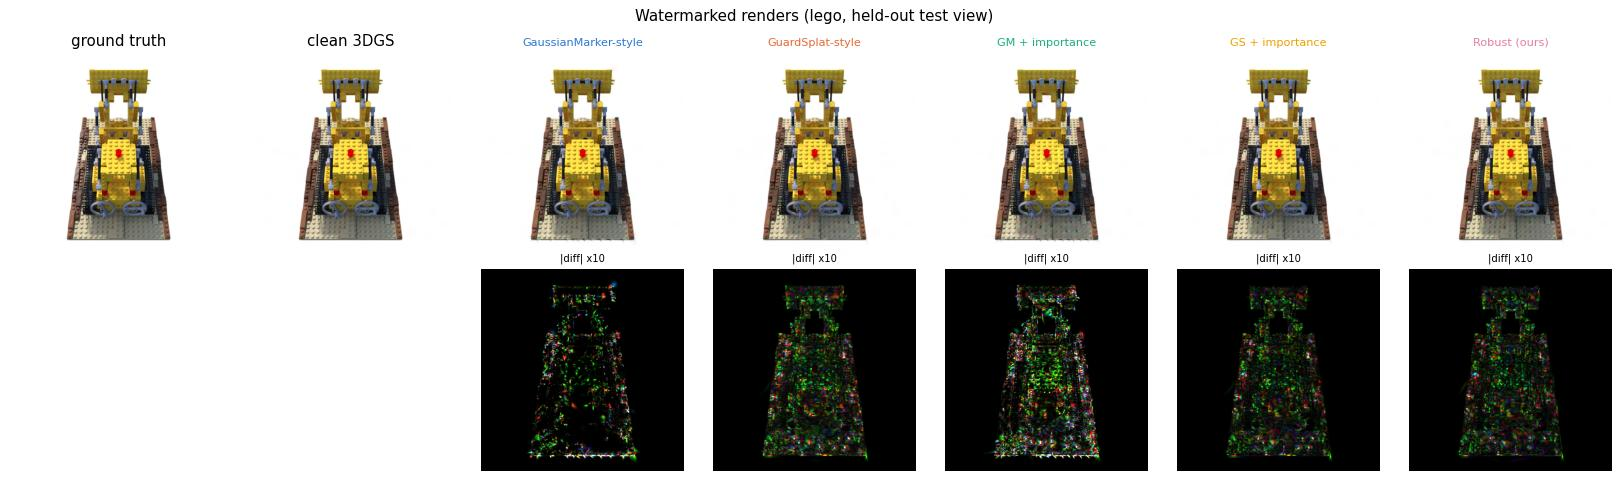

                      bit_acc  detect    psnr  psnr_vs_clean
method                                                      
no watermark            0.473   0.000  34.239            inf
GaussianMarker-style    0.731   0.458  33.385         44.403
GuardSplat-style        0.798   0.617  33.198         42.533
GM + importance         0.847   0.683  32.260         38.936
GS + importance         0.765   0.525  33.478         43.976
Robust (ours)           0.743   0.467  33.488         43.920


In [9]:
fig, axes = plt.subplots(2, 2 + len(METHODS), figsize=(2.6 * (2 + len(METHODS)), 5.4))
axes[0, 0].imshow(VIS['gt'][0]); axes[0, 0].set_title('ground truth')
axes[0, 1].imshow(VIS['clean'][0]); axes[0, 1].set_title('clean 3DGS')
axes[1, 0].axis('off'); axes[1, 1].axis('off')
for j, m in enumerate(METHODS, 2):
    axes[0, j].imshow(VIS['wm'][m][0]); axes[0, j].set_title(m, fontsize=9, color=COLORS[m])
    axes[1, j].imshow(((VIS['wm'][m][0] - VIS['clean'][0]).abs() * 10).clamp(0, 1))
    axes[1, j].set_title('|diff| x10', fontsize=8)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
plt.suptitle(f"Watermarked renders ({VIS['scene']}, held-out test view)")
plt.tight_layout(); savefig('watermark_examples', 'jpg')

emb = df[df.attack == 'none'].groupby('method')[['bit_acc', 'detect', 'psnr', 'psnr_vs_clean']].mean()
print(emb.loc[['no watermark'] + METHODS].round(3).to_string())

### Main result: bit accuracy vs. PSNR under benign operations
Each line is one method (mean over scenes); points along a line are increasing attack strength, starting from the
un-attacked watermarked scene (big marker). The grey band is chance level; the dashed line is the per-view
detection threshold.

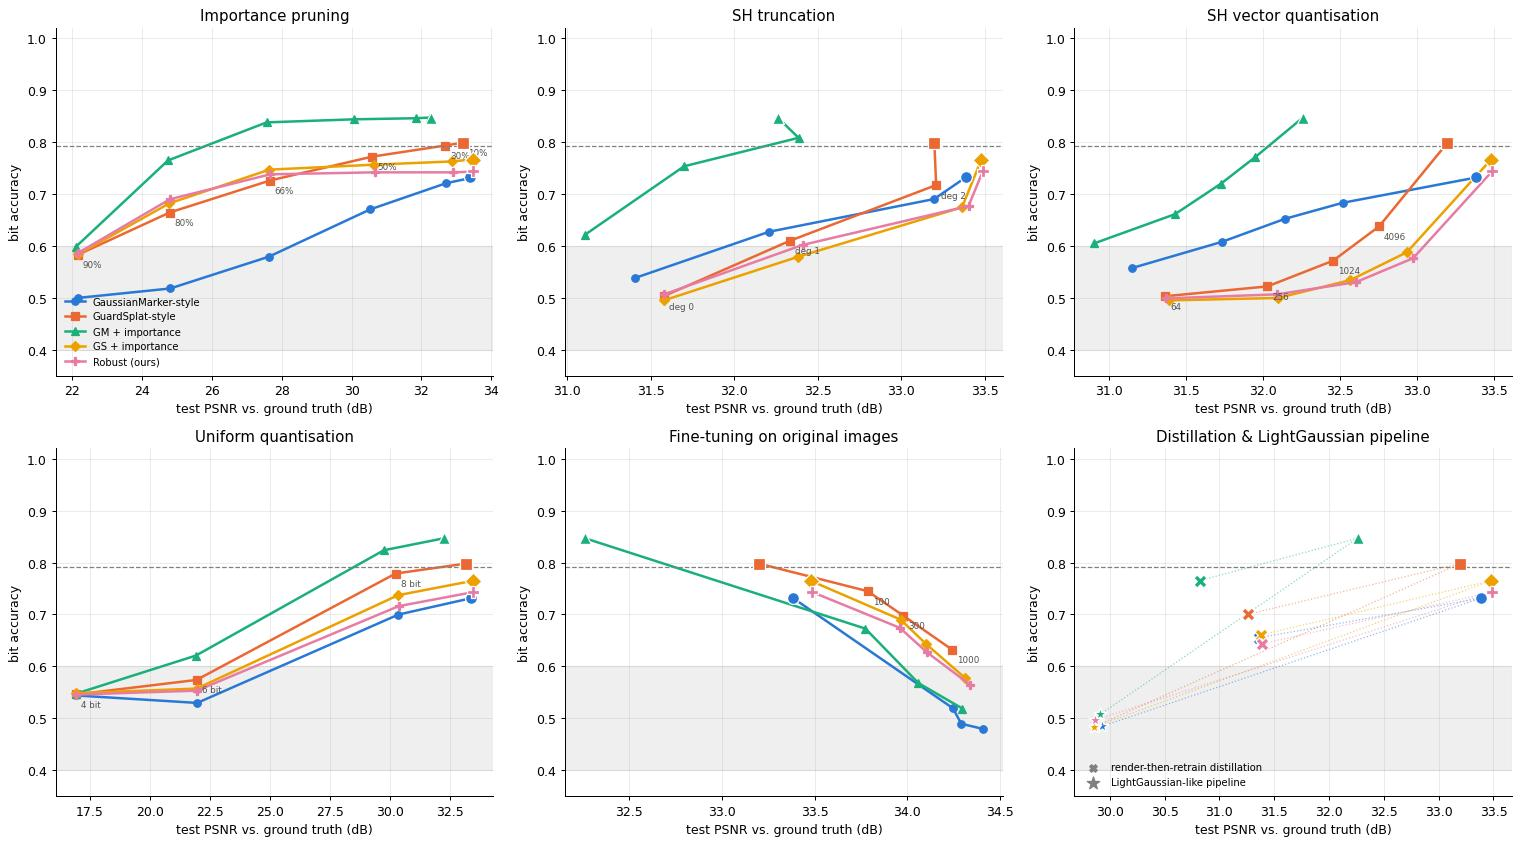

In [10]:
agg = df.groupby(['method', 'attack', 'strength'])[['bit_acc', 'detect', 'psnr', 'psnr_vs_clean', 'size_mb']].mean().reset_index()
PANELS = [('prune', 'Importance pruning', lambda s: f'{s:.0%}'), ('sh_degree', 'SH truncation', lambda s: f'deg {s:g}'),
          ('sh_vq', 'SH vector quantisation', lambda s: f'{s:g}'), ('quant', 'Uniform quantisation', lambda s: f'{s:g} bit'),
          ('finetune', 'Fine-tuning on original images', lambda s: f'{s:g}'),
          ('distill', 'Distillation & LightGaussian pipeline', None)]
fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))
for ax, (att, title, fmt) in zip(axes.flat, PANELS):
    for m in METHODS:
        base = agg[(agg.method == m) & (agg.attack == 'none')]
        ax.scatter(base.psnr, base.bit_acc, s=90, color=COLORS[m], marker=MARKERS[m], edgecolor='white', zorder=4)
        if att == 'distill':
            for a2, mk in [('distill', 'X'), ('lightgaussian', '*')]:
                p = agg[(agg.method == m) & (agg.attack == a2)]
                ax.scatter(p.psnr, p.bit_acc, s=110, color=COLORS[m], marker=mk, edgecolor='white', zorder=4)
                ax.plot([base.psnr.iloc[0], p.psnr.iloc[0]], [base.bit_acc.iloc[0], p.bit_acc.iloc[0]],
                        color=COLORS[m], lw=1, alpha=0.5, ls=':')
            continue
        sub = agg[(agg.method == m) & (agg.attack == att)]
        sub = sub.sort_values('strength', ascending=att in ('prune', 'finetune'))
        xs = [base.psnr.iloc[0]] + sub.psnr.tolist(); ys = [base.bit_acc.iloc[0]] + sub.bit_acc.tolist()
        ax.plot(xs, ys, '-', marker=MARKERS[m], color=COLORS[m], lw=2, ms=6, label=m)
        if m == METHODS[1]:
            for x_, y_, s_ in zip(sub.psnr, sub.bit_acc, sub.strength):
                ax.annotate(fmt(s_), (x_, y_), textcoords='offset points', xytext=(4, -10), fontsize=7, color='#52514e')
    ax.axhspan(0.4, 0.6, color='gray', alpha=0.12)
    ax.axhline(K_THR / N_BITS, color='gray', ls='--', lw=1)
    ax.set(title=title, xlabel='test PSNR vs. ground truth (dB)', ylabel='bit accuracy', ylim=(0.35, 1.02))
axes[0, 0].legend(frameon=False, fontsize=8, loc='lower left')
axes[1, 2].scatter([], [], marker='X', color='gray', label='render-then-retrain distillation')
axes[1, 2].scatter([], [], marker='*', color='gray', s=110, label='LightGaussian-like pipeline')
axes[1, 2].legend(frameon=False, fontsize=8, loc='lower left')
plt.tight_layout(); savefig('bitacc_vs_psnr')

### Compression ratio vs. watermark survival
The same points plotted against estimated storage. Compression that barely changes the file keeps the watermark
only if the method is robust.

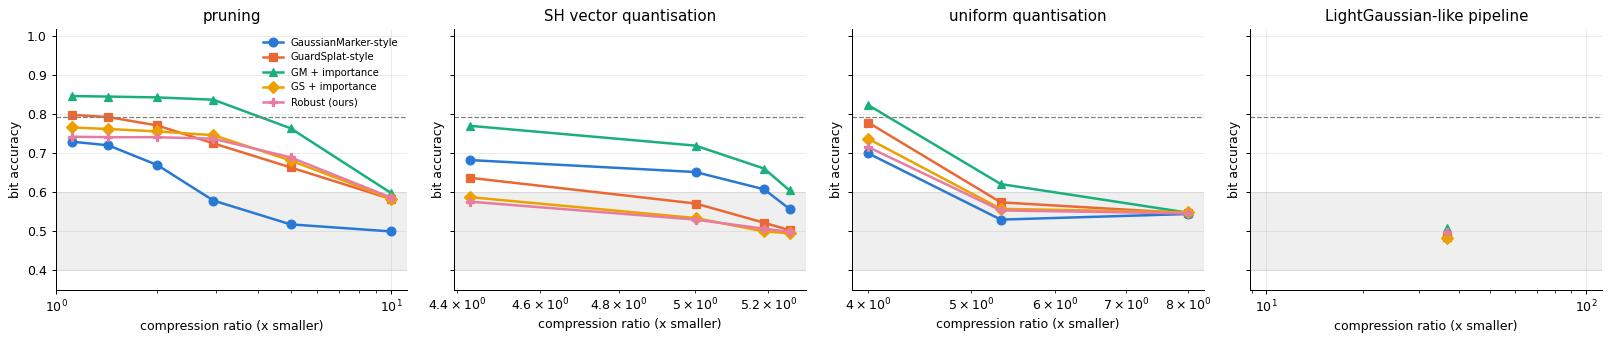

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.9), sharey=True)
for ax, att in zip(axes, ['prune', 'sh_vq', 'quant', 'lightgaussian']):
    for m in METHODS:
        base = agg[(agg.method == m) & (agg.attack == 'none')]
        sub = agg[(agg.method == m) & (agg.attack == att)]
        ratio = base.size_mb.iloc[0] / sub.size_mb
        ax.plot(ratio, sub.bit_acc, marker=MARKERS[m], color=COLORS[m], lw=2, ms=7, label=m,
                ls='-' if len(sub) > 1 else 'none')
    ax.axhspan(0.4, 0.6, color='gray', alpha=0.12); ax.axhline(K_THR / N_BITS, color='gray', ls='--', lw=1)
    ax.set(xscale='log', title={'prune': 'pruning', 'sh_vq': 'SH vector quantisation', 'quant': 'uniform quantisation',
                                'lightgaussian': 'LightGaussian-like pipeline'}[att],
           xlabel='compression ratio (x smaller)', ylabel='bit accuracy', ylim=(0.35, 1.02))
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); savefig('bitacc_vs_compression')

### Detection rate at typical settings
Share of held-out views in which the watermark is still detected (binomial test, FPR 1e-4), at settings a
practitioner would actually use.

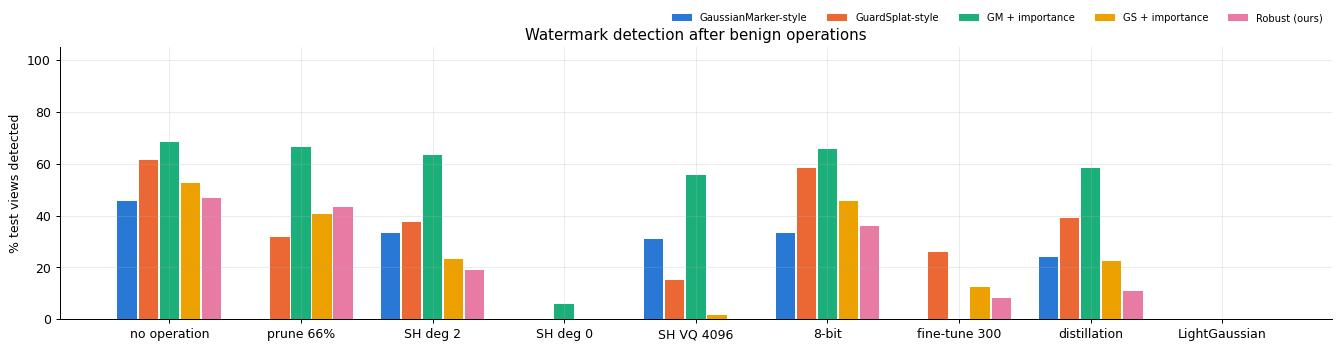

bit accuracy (mean over scenes):
                      no operation  prune 66%  SH deg 2  SH deg 0  SH VQ 4096  8-bit  fine-tune 300  distillation  LightGaussian
GaussianMarker-style         0.731      0.579     0.690     0.538       0.682  0.700          0.490         0.655          0.484
GuardSplat-style             0.798      0.725     0.717     0.503       0.637  0.779          0.698         0.700          0.484
GM + importance              0.847      0.837     0.808     0.621       0.770  0.824          0.568         0.765          0.508
GS + importance              0.765      0.746     0.674     0.495       0.587  0.737          0.643         0.660          0.483
Robust (ours)                0.743      0.737     0.676     0.506       0.576  0.716          0.627         0.644          0.497


In [12]:
TYPICAL = [('none', 0, 'no operation'), ('prune', 0.66, 'prune 66%'), ('sh_degree', 2, 'SH deg 2'),
           ('sh_degree', 0, 'SH deg 0'), ('sh_vq', 4096, 'SH VQ 4096'), ('quant', 8, '8-bit'),
           ('finetune', 300, 'fine-tune 300'), ('distill', DISTILL_ITERS, 'distillation'), ('lightgaussian', 1, 'LightGaussian')]
TYPICAL = [t for t in TYPICAL if ((agg.attack == t[0]) & (agg.strength == t[1])).any()]
fig, ax = plt.subplots(figsize=(15, 4))
w = 0.8 / len(METHODS)
for k, m in enumerate(METHODS):
    vals = [agg[(agg.method == m) & (agg.attack == a) & (agg.strength == s)].detect.iloc[0] for a, s, _ in TYPICAL]
    ax.bar(np.arange(len(TYPICAL)) + (k - (len(METHODS) - 1) / 2) * w, 100 * np.array(vals), w * 0.92,
           color=COLORS[m], label=m)
ax.set_xticks(range(len(TYPICAL)), [t[2] for t in TYPICAL])
ax.set(ylabel='% test views detected', ylim=(0, 105), title='Watermark detection after benign operations')
ax.legend(frameon=False, ncol=5, fontsize=8, loc='upper right', bbox_to_anchor=(1, 1.16))
plt.tight_layout(); savefig('detection_typical')

tab = pd.DataFrame({t[2]: [agg[(agg.method == m) & (agg.attack == t[0]) & (agg.strength == t[1])].bit_acc.iloc[0]
                           for m in METHODS] for t in TYPICAL}, index=METHODS)
print('bit accuracy (mean over scenes):'); print(tab.round(3).to_string())

### Strength-normalised robustness: watermark retention
Methods start from different bit accuracies, so we also report **retention** = (bit acc after - 0.5) /
(bit acc before - 0.5), computed per scene and averaged: 100% = the operation did not weaken the watermark at all,
0% = back to chance.

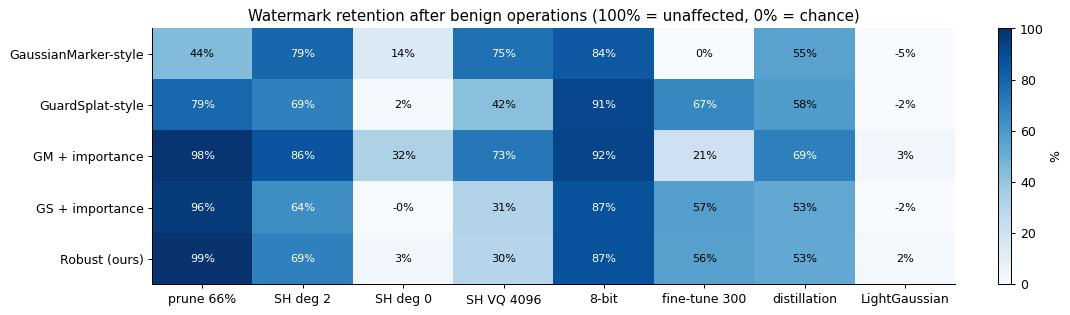

                      prune 66%  SH deg 2  SH deg 0  SH VQ 4096  8-bit  fine-tune 300  distillation  LightGaussian
GaussianMarker-style       0.44      0.79      0.14        0.75   0.84           0.00          0.55          -0.05
GuardSplat-style           0.79      0.69      0.02        0.42   0.91           0.67          0.58          -0.02
GM + importance            0.98      0.86      0.32        0.73   0.92           0.21          0.69           0.03
GS + importance            0.96      0.64     -0.00        0.31   0.87           0.57          0.53          -0.02
Robust (ours)              0.99      0.69      0.03        0.30   0.87           0.56          0.53           0.02


In [13]:
base_acc = df[df.attack == 'none'].set_index(['scene', 'method']).bit_acc
df['retention'] = [(r.bit_acc - 0.5) / max(base_acc[(r.scene, r.method)] - 0.5, 1e-6) for r in df.itertuples()]
ret = pd.DataFrame({t[2]: [df[(df.method == m) & (df.attack == t[0]) & (df.strength == t[1])].retention.mean()
                           for m in METHODS] for t in TYPICAL[1:]}, index=METHODS)
fig, ax = plt.subplots(figsize=(12, 3.6))
im = ax.imshow(100 * ret.values.clip(0, 1.2), cmap='Blues', vmin=0, vmax=100, aspect='auto')
for i_ in range(ret.shape[0]):
    for j_ in range(ret.shape[1]):
        v = 100 * ret.values[i_, j_]
        ax.text(j_, i_, f'{v:.0f}%', ha='center', va='center', fontsize=9, color='white' if v > 60 else 'black')
ax.set_xticks(range(ret.shape[1]), ret.columns); ax.set_yticks(range(ret.shape[0]), ret.index); ax.grid(False)
ax.set_title('Watermark retention after benign operations (100% = unaffected, 0% = chance)')
plt.colorbar(im, ax=ax, fraction=0.02, label='%')
plt.tight_layout(); savefig('retention')
print(ret.round(2).to_string())

### Why does pruning hurt? Where the watermark lives
Left: every Gaussian of the first scene by importance and uncertainty. GaussianMarker-style embedding picks the
high-uncertainty Gaussians (orange). The dashed line is the importance cut of 66% pruning: everything left of it is
deleted. Right: for each method, the share of carrier Gaussians and of the total parameter change that sits on
Gaussians removed by 66% pruning.

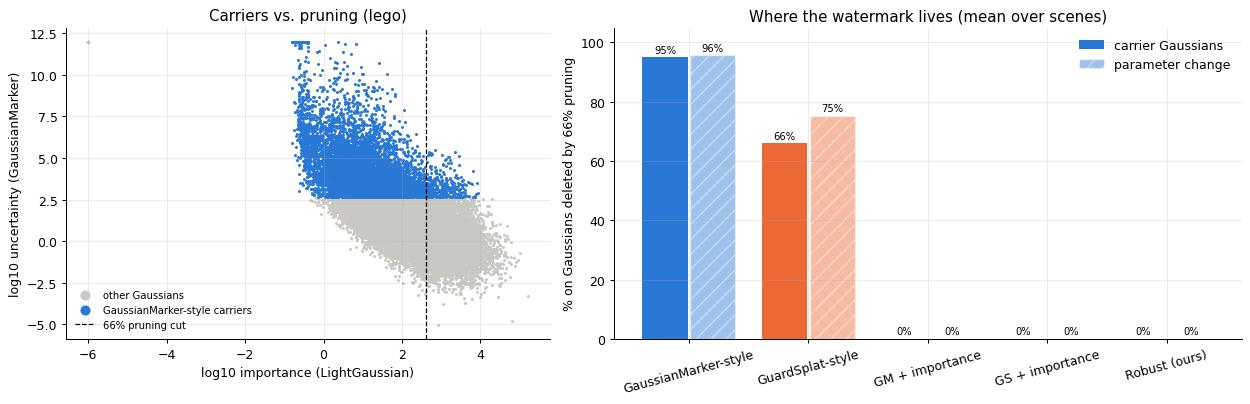

                        carriers  carriers_pruned_by_66  change_on_pruned
method                                                                   
GM + importance        20264.333                  0.000             0.000
GS + importance        34450.000                  0.000             0.000
GaussianMarker-style   20264.333                  0.949             0.957
GuardSplat-style      101323.000                  0.660             0.752
Robust (ours)          34450.000                  0.000             0.000


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw=dict(width_ratios=[1, 1.3]))
imp_, unc_ = VIS['imp'].numpy(), VIS['unc'].numpy()
sel = np.random.default_rng(0).choice(len(imp_), min(40000, len(imp_)), replace=False)
gm = VIS['gm_mask'].numpy()
x, y = np.log10(imp_ + 1e-6), np.log10(unc_ + 1e-30)
axes[0].scatter(x[sel][~gm[sel]], y[sel][~gm[sel]], s=2, color='#c9c8c2', label='other Gaussians', rasterized=True)
axes[0].scatter(x[sel][gm[sel]], y[sel][gm[sel]], s=2, color=COLORS['GaussianMarker-style'], label='GaussianMarker-style carriers', rasterized=True)
axes[0].axvline(np.log10(np.quantile(imp_, 0.66) + 1e-6), color='black', ls='--', lw=1, label='66% pruning cut')
axes[0].set(xlabel='log10 importance (LightGaussian)', ylabel='log10 uncertainty (GaussianMarker)',
            title=f"Carriers vs. pruning ({VIS['scene']})")
axes[0].legend(frameon=False, markerscale=5, fontsize=8)
mm = MECH.groupby('method')[['carriers_pruned_by_66', 'change_on_pruned']].mean().loc[METHODS]
xx = np.arange(len(METHODS))
axes[1].bar(xx - 0.2, 100 * mm.carriers_pruned_by_66, 0.38, color=[COLORS[m] for m in METHODS], label='carrier Gaussians')
axes[1].bar(xx + 0.2, 100 * mm.change_on_pruned, 0.38, color=[COLORS[m] for m in METHODS], alpha=0.45, hatch='//',
            edgecolor='white', label='parameter change')
for k, m in enumerate(METHODS):
    axes[1].text(k - 0.2, 100 * mm.carriers_pruned_by_66[m] + 1.5, f'{mm.carriers_pruned_by_66[m]:.0%}', ha='center', fontsize=8)
    axes[1].text(k + 0.2, 100 * mm.change_on_pruned[m] + 1.5, f'{mm.change_on_pruned[m]:.0%}', ha='center', fontsize=8)
axes[1].set_xticks(xx, METHODS, rotation=15)
axes[1].set(ylabel='% on Gaussians deleted by 66% pruning', ylim=(0, 105), title='Where the watermark lives (mean over scenes)')
axes[1].legend(frameon=False)
plt.tight_layout(); savefig('mechanism')
print(MECH.groupby('method')[['carriers', 'carriers_pruned_by_66', 'change_on_pruned']].mean().round(3).to_string())

### Visual check: what the attacks do to the image

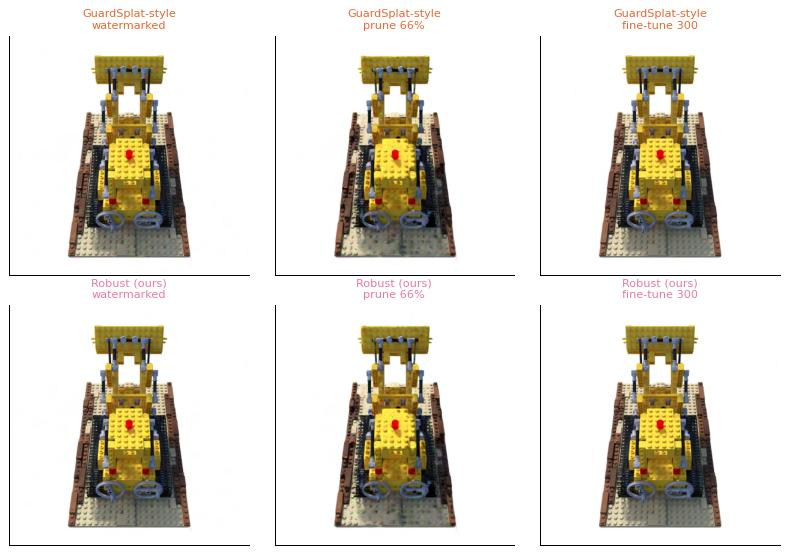

In [15]:
ex = VIS['examples']
fig, axes = plt.subplots(len(ex), 3, figsize=(9, 3.1 * len(ex)))
for r_, (m, d) in enumerate(ex.items()):
    for c_, (k, im) in enumerate(d.items()):
        axes[r_, c_].imshow(im[0]); axes[r_, c_].set_title(f'{m}\n{k}', fontsize=9, color=COLORS[m])
        axes[r_, c_].set_xticks([]); axes[r_, c_].set_yticks([]); axes[r_, c_].grid(False)
plt.tight_layout(); savefig('attack_examples', 'jpg')

### Per-scene numbers

In [16]:
per_scene = df[df.attack.isin(['none', 'prune', 'finetune', 'distill', 'lightgaussian'])]
per_scene = per_scene[(per_scene.attack == 'none') | ((per_scene.attack == 'prune') & (per_scene.strength == 0.66))
                      | ((per_scene.attack == 'finetune') & (per_scene.strength == 300))
                      | per_scene.attack.isin(['distill', 'lightgaussian'])]
print(per_scene.pivot_table(index=['method'], columns=['attack', 'scene'], values='bit_acc').round(2).to_string())
agg.to_csv(f'{OUT}/results_mean.csv', index=False)
print(f'\ntotal runtime: {(time.time() - T0) / 60:.1f} min')

attack               distill              finetune              lightgaussian               none              prune             
scene                  ficus hotdog  lego    ficus hotdog  lego         ficus hotdog  lego ficus hotdog  lego ficus hotdog  lego
method                                                                                                                          
GM + importance         0.57   0.83  0.89     0.56   0.55  0.60          0.52   0.50  0.50  0.71   0.90  0.93  0.71   0.88  0.92
GS + importance         0.53   0.70  0.75     0.59   0.63  0.71          0.51   0.48  0.46  0.63   0.80  0.87  0.63   0.77  0.84
GaussianMarker-style    0.52   0.65  0.79     0.51   0.48  0.47          0.50   0.48  0.47  0.58   0.73  0.89  0.56   0.55  0.63
GuardSplat-style        0.54   0.76  0.80     0.59   0.71  0.78          0.51   0.47  0.46  0.64   0.86  0.90  0.62   0.74  0.81
Robust (ours)           0.53   0.67  0.73     0.58   0.61  0.69          0.52   0.48  0.49  0.61 

## 9. Conclusions

**1. A standard compression pipeline silently erases every watermark.** The LightGaussian-like pipeline (prune 66%
→ 500 recovery steps → SH degree 2 → SH VQ 4096 → 8-bit) keeps the scene usable (about 30 dB test PSNR vs. 33.4 dB)
but drives *every* method back to chance: retention is between −5% and +3%, including the fixes. Nobody attacked
the watermark; the scene was simply compressed.

**2. GaussianMarker-style selection is anti-aligned with pruning.** High-uncertainty Gaussians are, almost by
definition, the ones that barely affect the renders, and those are exactly what importance pruning deletes first:
**95% of the carriers** fall below LightGaussian's 66% cut. Pruning 66% keeps only **44%** of that watermark, against
79% for the GuardSplat-style embedding (which spreads over all Gaussians).

**3. The simple fix works for pruning.** Embedding only in the top-34% most important Gaussians raises retention
after 66% pruning to **96–99%** for both families. GM + importance is also the strongest method overall (0.85 bit
accuracy before any operation; best or tied-best retention for pruning, SH degree 2, 8-bit and distillation). It does
cost more image quality (38.9 dB vs. ~44 dB PSNR against the clean scene), and the retention metric only partly
controls for that.

**4. Pruning is not the only threat; each family has its own weak spot.**
- *Fine-tuning* for 300 steps on the original images erases geometry-carried watermarks (GaussianMarker-style 0%,
  GM + importance 21%). SH-carried ones keep 56–67%.
- *SH truncation to degree 0* erases SH-carried watermarks (0–3%): GuardSplat-style embedding lives mostly in the
  view-dependent SH bands, and SH VQ 4096 already removes more than half of it (30–42%).
- *8-bit quantisation* is harmless (84–92%).

**5. Render-then-retrain distillation does *not* remove the watermark.** A fresh 3DGS trained only on renders keeps
53–69% of it, because the watermark is in the pixels and the student re-learns it. For provenance this is good news:
render-space watermarks transfer to derived models.

**6. Compression-aware augmentation did not help.** "Robust (ours)" (importance carriers + simulated pruning, SH
truncation and SH noise during embedding) is no better than importance carriers alone. The failure modes that matter
(fine-tuning, SH truncation, the full pipeline) need a different carrier, e.g. mixing geometry, DC colour and
view-dependent SH, or fine-tuning-aware embedding. This is a clear direction for future work.

**Caveats.** These are simplified re-implementations of the two *embedding strategies* with one shared public decoder
(HiDDeN, 48 bits), not the authors' full systems. Our operating point (0.73–0.85 bit accuracy at 39–44 dB) is weaker
than the papers report. The study covers 3 NeRF-synthetic scenes at 400×400 (ficus, with its thin leaves, is the
hardest), and importance uses a projected-area proxy for LightGaussian's pixel count.